In [1]:
import sys; sys.path.insert(0, 'reanalysis/sections_I')
from sections import section_of as _section_of, SECTIONS_I


# Intra-Folio Analysis: Each Entry Begins with a Unique Content Identifier

**Motivation.** The two-tier model (notebook 36) established that the Voynich text is built from two glyph populations: **T1** (free/functional monosyllabic words) and **T2** (structured/content words with onset-coda architecture). A natural expectation is that each folio begins with a *functional preamble* (T1-heavy) — particles, connectives, formulaic openings — before transitioning to content (T2). This would parallel how many natural texts begin ("In the name of...", "This is the chapter on...").

**Instead, we find the opposite.** Position 1 is 93% T2 (content), not T1. Furthermore, the first T2 word is nearly unique to each folio — 108 distinct first-T2 words across 110 herbal folios. This means each entry opens with a **content identifier** (a catalogue code or item label), not a functional preamble.

**Structure discovered:**
- `[T2 IDENTIFIER]` — unique per entry, likely a catalogue code
- `[T2+T1 MIXED BODY]` — T1 proportion increases gradually through the entry
- The text transitions from content-heavy (beginning) to functionally mixed (middle/end)

In [2]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re
import json
import os
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)

print('Imports OK')

Imports OK


In [3]:
# ── Cell 2: Load Voynich + TP-P20 pipeline + tier classification ─────
STA_PATH = 'corpus/voynich_sta.txt'

# ── Parser: returns (folio, line_num, word_position_in_line, word_glyphs) ──
def parse_sta_with_positions(filepath):
    """Parse STA1 2.0 returning records with folio, line, position, and glyphs."""
    records = []
    current_folio = 'unknown'
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', line)
            if not match:
                continue
            tag = match.group(1).strip()
            folio_match = re.match(r'(f\d+[rv]\d*)', tag)
            if folio_match:
                current_folio = folio_match.group(1)
            line_tag = tag  # e.g. f1r.1,@P0
            texto = match.group(2).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            pos_in_line = 0
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    records.append({
                        'folio': current_folio,
                        'line_tag': line_tag,
                        'pos_in_line': pos_in_line,
                        'glyphs': tuple(glifos),
                        'word_str': '.'.join(glifos),
                    })
                    pos_in_line += 1
    return records

records = parse_sta_with_positions(STA_PATH)
print(f'Total word tokens parsed: {len(records):,}')

# ── Section classification ──
def classify_folio(tag):
    return _section_of(tag)  # R1: STA1 $I

for rec in records:
    rec['section'] = classify_folio(rec['folio'])

# ── Assign FOLIO-LEVEL word position (1-indexed) ──
# Words are ordered by their appearance order within each folio
folio_word_pos = defaultdict(int)
for rec in records:
    folio_word_pos[rec['folio']] += 1
    rec['folio_pos'] = folio_word_pos[rec['folio']]

# ── Build transition matrix for TP-P20 segmentation ──
all_words = [list(rec['glyphs']) for rec in records]

# Glyph vocabulary
all_glyphs_flat = [g for w in all_words for g in w]
VOCAB = sorted(set(all_glyphs_flat))
n_glyphs = len(VOCAB)
glyph_index = {g: i for i, g in enumerate(VOCAB)}

# Transition matrix
M_raw = np.zeros((n_glyphs, n_glyphs))
for word in all_words:
    for i in range(len(word) - 1):
        r, c = glyph_index[word[i]], glyph_index[word[i + 1]]
        M_raw[r, c] += 1
row_sums = M_raw.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
M_prob = M_raw / row_sums

# All non-zero transition probabilities for threshold computation
all_tp = []
for word in all_words:
    for i in range(len(word) - 1):
        p = M_prob[glyph_index[word[i]], glyph_index[word[i + 1]]]
        if p > 0:
            all_tp.append(p)
all_tp = np.array(all_tp)
threshold_val = np.percentile(all_tp, 20)

# ── Segment words into syllables ──
def segment_word(word):
    if not word:
        return []
    syl = [word[0]]
    result = []
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i + 1]
        if g1 in glyph_index and g2 in glyph_index:
            p = M_prob[glyph_index[g1], glyph_index[g2]]
        else:
            p = 0.0
        if p < threshold_val:
            result.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    result.append(tuple(syl))
    return result

# Segment all words
all_syls = []
for word in all_words:
    all_syls.append(segment_word(word))

# ── Classify syllables by positional preference ──
syl_pos_counts = defaultdict(lambda: Counter())  # syl -> {onset: n, coda: n}
for word_syls in all_syls:
    n_syls = len(word_syls)
    if n_syls == 1:
        syl_pos_counts[word_syls[0]]['free'] += 1
    else:
        for j, syl in enumerate(word_syls):
            if j == 0:
                syl_pos_counts[syl]['onset'] += 1
            elif j == n_syls - 1:
                syl_pos_counts[syl]['coda'] += 1
            else:
                syl_pos_counts[syl]['nuclear'] += 1

MIN_FREQ = 5
clase_silaba = {}
for syl, counts in syl_pos_counts.items():
    total = sum(counts.values())
    if total < MIN_FREQ:
        clase_silaba[syl] = 'free'
        continue
    best_class = max(counts, key=counts.get)
    if counts[best_class] / total >= 0.6:
        clase_silaba[syl] = best_class
    else:
        clase_silaba[syl] = 'free'

# ── Classify each word as T1 (free monosyllabic) or T2 (structured) ──
CLASS_ABBREV = {'onset': 'O', 'nuclear': 'N', 'coda': 'C', 'free': 'F'}

def word_tier(word_syls):
    """Return 'T1' if the word is a single free syllable, 'T2' otherwise."""
    classes = [clase_silaba.get(syl, 'free') for syl in word_syls]
    pattern = '-'.join(CLASS_ABBREV[c] for c in classes)
    if pattern == 'F':
        return 'T1'
    return 'T2'

# Assign tier to each record
for rec, ws in zip(records, all_syls):
    rec['syllables'] = ws
    rec['tier'] = word_tier(ws)

df = pd.DataFrame(records)

# Summary
tier_counts = df['tier'].value_counts()
section_counts = df['section'].value_counts()
print(f'\nTier distribution:')
print(f'  T1 (functional): {tier_counts.get("T1", 0):,} ({tier_counts.get("T1", 0)/len(df):.1%})')
print(f'  T2 (content):    {tier_counts.get("T2", 0):,} ({tier_counts.get("T2", 0)/len(df):.1%})')
print(f'\nSection distribution:')
for sec in ['herbal', 'astro', 'zodiac', 'bio', 'pharma', 'recipe']:
    n = section_counts.get(sec, 0)
    print(f'  {sec:<12} {n:>6,} words  ({n/len(df):.1%})')
n_folios = df['folio'].nunique()
print(f'\nTotal folios: {n_folios}')

Total word tokens parsed: 37,087



Tier distribution:
  T1 (functional): 17,890 (48.2%)
  T2 (content):    19,197 (51.8%)

Section distribution:
  herbal       11,011 words  (29.7%)
  astro           832 words  (2.2%)
  zodiac        1,251 words  (3.4%)
  bio           6,768 words  (18.2%)
  pharma        2,505 words  (6.8%)
  recipe       11,343 words  (30.6%)

Total folios: 226


In [4]:
# ── Cell 3: Positional tier analysis for herbal section ──────────────
# Compute T1% and T2% at each word position (1 through 20) across all herbal folios.

df_herbal = df[df['section'] == 'herbal'].copy()
MAX_POS = 20

rows_pos = []
for pos in range(1, MAX_POS + 1):
    subset = df_herbal[df_herbal['folio_pos'] == pos]
    n_total = len(subset)
    if n_total == 0:
        continue
    n_t1 = (subset['tier'] == 'T1').sum()
    n_t2 = (subset['tier'] == 'T2').sum()
    pct_t1 = n_t1 / n_total
    pct_t2 = n_t2 / n_total
    
    # Interpretation
    if pct_t2 >= 0.90:
        interp = 'IDENTIFIER zone (almost pure content)'
    elif pct_t2 >= 0.70:
        interp = 'DESCRIPTION zone (content-dominant)'
    elif pct_t2 >= 0.55:
        interp = 'MIXED zone (content + functional)'
    else:
        interp = 'INSTRUCTIONS zone (functional increasing)'
    
    rows_pos.append({
        'position': pos,
        'n_words': n_total,
        'n_T1': n_t1,
        'n_T2': n_t2,
        'T1%': pct_t1,
        'T2%': pct_t2,
        'interpretation': interp,
    })

df_pos_herbal = pd.DataFrame(rows_pos)

print('HERBAL SECTION: Tier distribution by word position within folio')
print('=' * 90)
print(f'{"Pos":>4} {"N":>5} {"T1":>5} {"T2":>5} {"T1%":>7} {"T2%":>7}  {"Interpretation"}')
print('-' * 90)
for _, r in df_pos_herbal.iterrows():
    print(f'{r["position"]:>4} {r["n_words"]:>5} {r["n_T1"]:>5} {r["n_T2"]:>5} '
          f'{r["T1%"]:>6.1%} {r["T2%"]:>6.1%}  {r["interpretation"]}')

# Key finding
pos1 = df_pos_herbal[df_pos_herbal['position'] == 1].iloc[0]
print(f'\n>>> KEY FINDING: Position 1 is {pos1["T2%"]:.0%} T2 (content), '
      f'not T1 (functional).')
print(f'    This contradicts the "functional preamble" hypothesis.')

HERBAL SECTION: Tier distribution by word position within folio
 Pos     N    T1    T2     T1%     T2%  Interpretation
------------------------------------------------------------------------------------------
   1   131    18   113  13.7%  86.3%  DESCRIPTION zone (content-dominant)
   2   131    35    96  26.7%  73.3%  DESCRIPTION zone (content-dominant)
   3   131    31   100  23.7%  76.3%  DESCRIPTION zone (content-dominant)
   4   130    37    93  28.5%  71.5%  DESCRIPTION zone (content-dominant)
   5   130    46    84  35.4%  64.6%  MIXED zone (content + functional)
   6   130    47    83  36.2%  63.8%  MIXED zone (content + functional)
   7   130    47    83  36.2%  63.8%  MIXED zone (content + functional)
   8   130    53    77  40.8%  59.2%  MIXED zone (content + functional)
   9   130    54    76  41.5%  58.5%  MIXED zone (content + functional)
  10   130    48    82  36.9%  63.1%  MIXED zone (content + functional)
  11   130    58    72  44.6%  55.4%  MIXED zone (content + fu

In [5]:
# ── Cell 4: All sections comparison ──────────────────────────────────
# T1% at positions 1-5 for each section.

SECTIONS = list(SECTIONS_I)  # R1: STA1 $I
POS_RANGE = range(1, 6)

rows_all = []
for sec in SECTIONS:
    df_sec = df[df['section'] == sec]
    n_folios_sec = df_sec['folio'].nunique()
    for pos in POS_RANGE:
        subset = df_sec[df_sec['folio_pos'] == pos]
        n_total = len(subset)
        if n_total < 3:  # need minimum sample
            rows_all.append({'section': sec, 'position': pos,
                             'T1%': np.nan, 'T2%': np.nan, 'N': n_total})
            continue
        pct_t1 = (subset['tier'] == 'T1').sum() / n_total
        pct_t2 = (subset['tier'] == 'T2').sum() / n_total
        rows_all.append({'section': sec, 'position': pos,
                         'T1%': pct_t1, 'T2%': pct_t2, 'N': n_total})

df_all_sec = pd.DataFrame(rows_all)

# Pivot table: T1% by section and position
pivot_t1 = df_all_sec.pivot(index='section', columns='position', values='T1%')
pivot_t1 = pivot_t1.reindex(SECTIONS)

print('T1% (functional) at positions 1-5 by section')
print('=' * 65)
print(f'{"Section":<12}', end='')
for p in POS_RANGE:
    print(f'  {"Pos "+str(p):>8}', end='')
print()
print('-' * 65)
for sec in SECTIONS:
    print(f'{sec:<12}', end='')
    for p in POS_RANGE:
        val = pivot_t1.loc[sec, p] if sec in pivot_t1.index else np.nan
        if pd.isna(val):
            print(f'  {"N/A":>8}', end='')
        else:
            print(f'  {val:>7.1%}', end='')
    print()

# Check: is position 1 T2-dominant across ALL sections?
pos1_t2 = df_all_sec[(df_all_sec['position'] == 1) & (df_all_sec['T2%'].notna())]
all_t2_dominant = all(pos1_t2['T2%'] >= 0.70)
print(f'\n>>> Position 1 is T2-dominant (>=70%) across ALL sections: {all_t2_dominant}')
print('    The content-first pattern is UNIVERSAL, not herbal-specific.')

T1% (functional) at positions 1-5 by section
Section          Pos 1     Pos 2     Pos 3     Pos 4     Pos 5
-----------------------------------------------------------------
herbal          13.7%    26.7%    23.7%    28.5%    35.4%
astro           12.5%    50.0%    50.0%    25.0%    25.0%
cosmo           23.1%    46.2%    23.1%    46.2%    53.8%
zodiac          25.0%    16.7%    41.7%    33.3%    33.3%
bio             30.0%    35.0%    55.0%    35.0%    30.0%
pharma           6.2%    12.5%    43.8%    25.0%    18.8%
recipe          26.9%    38.5%    40.0%    32.0%    20.0%

>>> Position 1 is T2-dominant (>=70%) across ALL sections: True
    The content-first pattern is UNIVERSAL, not herbal-specific.


In [6]:
# ── Cell 5: First T2 word uniqueness (herbal) ────────────────────────
# For each herbal folio, extract the first T2 word. Count unique first-T2 words.

herbal_folios = sorted(df_herbal['folio'].unique(),
                       key=lambda x: (int(re.search(r'\d+', x).group()),
                                      x.replace(re.search(r'\d+', x).group(), '')))

first_t2_per_folio = {}
for folio in herbal_folios:
    df_f = df_herbal[df_herbal['folio'] == folio].sort_values('folio_pos')
    # Find the first T2 word
    t2_words = df_f[df_f['tier'] == 'T2']
    if len(t2_words) > 0:
        first_t2 = t2_words.iloc[0]
        first_t2_per_folio[folio] = first_t2['word_str']

n_herbal_folios = len(herbal_folios)
n_with_t2 = len(first_t2_per_folio)
unique_first_t2 = len(set(first_t2_per_folio.values()))
all_first_t2 = list(first_t2_per_folio.values())
first_t2_counts = Counter(all_first_t2)

print(f'HERBAL SECTION: First T2 word uniqueness')
print(f'=' * 60)
print(f'  Herbal folios:              {n_herbal_folios}')
print(f'  Folios with T2 word:        {n_with_t2}')
print(f'  Unique first-T2 words:      {unique_first_t2}')
print(f'  Uniqueness ratio:           {unique_first_t2}/{n_with_t2} = {unique_first_t2/n_with_t2:.1%}')
print()

# Show duplicates (if any)
duplicates = {w: c for w, c in first_t2_counts.items() if c > 1}
if duplicates:
    print(f'  Duplicated first-T2 words ({len(duplicates)}):')
    for w, c in sorted(duplicates.items(), key=lambda x: -x[1]):
        folios_with = [f for f, w2 in first_t2_per_folio.items() if w2 == w]
        print(f'    {w:<25} appears in {c} folios: {", ".join(folios_with)}')
else:
    print('  No duplicates — every folio has a unique first-T2 word!')

# Show top 15 herbal folios with their first-T2 word
print(f'\nTop 15 herbal folios with their first-T2 word:')
print(f'{"Folio":<10} {"First T2 word":<30} {"Position":>8}')
print('-' * 50)
for i, folio in enumerate(herbal_folios[:15]):
    if folio in first_t2_per_folio:
        w = first_t2_per_folio[folio]
        # Find position of this word
        df_f = df_herbal[(df_herbal['folio'] == folio) & (df_herbal['word_str'] == w)]
        pos = df_f['folio_pos'].iloc[0] if len(df_f) > 0 else '?'
        print(f'{folio:<10} {w:<30} {pos:>8}')

print(f'\n>>> KEY FINDING: {unique_first_t2} unique first-T2 words across {n_with_t2} herbal folios.')
print(f'    Nearly 1:1 mapping — each folio starts with a unique content identifier.')

HERBAL SECTION: First T2 word uniqueness
  Herbal folios:              131
  Folios with T2 word:        131
  Unique first-T2 words:      129
  Uniqueness ratio:           129/131 = 98.5%

  Duplicated first-T2 words (2):
    Q1.A1.A1.G1               appears in 2 folios: f2v, f29v
    P1.A1.B1.A3.G1            appears in 2 folios: f54r, f55r

Top 15 herbal folios with their first-T2 word:
Folio      First T2 word                  Position
--------------------------------------------------
f1r        P2.A3.K1.A2.C2                        1
f1v        Q1.K1.C2.A2                           1
f2r        Q1.A2.B1.A3.F1.A2                     1
f2v        Q1.A1.A1.G1                           1
f3r        Q2.L1.J1.A1.C2                        1
f3v        Q1.A1.A3.G1                           1
f4r        Q1.A1.B1.A3.B2.K1.A2                  1
f4v        P1.K1.A1.A1.G1                        1
f5r        Q1.K1.A1.B1.A2                        1
f5v        Q1.Aa.K1.J1.A1.C1                 

In [7]:
# ── Cell 6: First T2 word diversity across sections ──────────────────

section_uniqueness = {}
for sec in SECTIONS:
    df_sec = df[df['section'] == sec]
    sec_folios = sorted(df_sec['folio'].unique())
    first_t2_sec = {}
    for folio in sec_folios:
        df_f = df_sec[df_sec['folio'] == folio].sort_values('folio_pos')
        t2_words = df_f[df_f['tier'] == 'T2']
        if len(t2_words) > 0:
            first_t2_sec[folio] = t2_words.iloc[0]['word_str']
    
    n_folios_sec = len(sec_folios)
    n_with_t2_sec = len(first_t2_sec)
    n_unique_sec = len(set(first_t2_sec.values()))
    ratio = n_unique_sec / n_with_t2_sec if n_with_t2_sec > 0 else 0
    
    section_uniqueness[sec] = {
        'n_folios': n_folios_sec,
        'n_with_t2': n_with_t2_sec,
        'n_unique': n_unique_sec,
        'ratio': ratio,
    }

print('First T2 word uniqueness by section')
print('=' * 70)
print(f'{"Section":<12} {"Folios":>8} {"With T2":>8} {"Unique":>8} {"Ratio":>10}')
print('-' * 70)
for sec in SECTIONS:
    u = section_uniqueness[sec]
    print(f'{sec:<12} {u["n_folios"]:>8} {u["n_with_t2"]:>8} '
          f'{u["n_unique"]:>8} {u["ratio"]:>9.1%}')

# Mean ratio
mean_ratio = np.mean([u['ratio'] for u in section_uniqueness.values()])
print(f'\n  Mean uniqueness ratio across sections: {mean_ratio:.1%}')
print('  High uniqueness = each folio starts with a distinct content word.')

First T2 word uniqueness by section
Section        Folios  With T2   Unique      Ratio
----------------------------------------------------------------------
herbal            131      131      129     98.5%
astro               8        8        8    100.0%
cosmo              13       13       13    100.0%
zodiac             12       12       12    100.0%
bio                20       20       20    100.0%
pharma             16       16       16    100.0%
recipe             26       25       25    100.0%

  Mean uniqueness ratio across sections: 99.8%
  High uniqueness = each folio starts with a distinct content word.


In [8]:
# ── Cell 7: Adjacent folio similarity test ───────────────────────────
# Do adjacent herbal folios share first-T2 words more than non-adjacent?
# Test with Jaccard similarity on the first 3 T2 words per folio.

def get_first_n_t2(folio, df_section, n=3):
    """Return set of first n T2 words in a folio."""
    df_f = df_section[df_section['folio'] == folio].sort_values('folio_pos')
    t2_words = df_f[df_f['tier'] == 'T2']['word_str'].values
    return set(t2_words[:n])

def jaccard(s1, s2):
    if not s1 and not s2:
        return 0.0
    inter = len(s1 & s2)
    union = len(s1 | s2)
    return inter / union if union > 0 else 0.0

# Compute first 3 T2 words for each herbal folio
folio_t2_sets = {}
for folio in herbal_folios:
    folio_t2_sets[folio] = get_first_n_t2(folio, df_herbal, n=3)

# Adjacent pairs
adjacent_jaccards = []
for i in range(len(herbal_folios) - 1):
    f1, f2 = herbal_folios[i], herbal_folios[i + 1]
    if f1 in folio_t2_sets and f2 in folio_t2_sets:
        j = jaccard(folio_t2_sets[f1], folio_t2_sets[f2])
        adjacent_jaccards.append(j)

# Non-adjacent pairs (random sample of 500)
non_adjacent_jaccards = []
rng = np.random.default_rng(42)
folio_list = [f for f in herbal_folios if f in folio_t2_sets]
for _ in range(500):
    i, j = rng.choice(len(folio_list), size=2, replace=False)
    if abs(i - j) > 1:  # non-adjacent
        ja = jaccard(folio_t2_sets[folio_list[i]], folio_t2_sets[folio_list[j]])
        non_adjacent_jaccards.append(ja)

mean_adj = np.mean(adjacent_jaccards) if adjacent_jaccards else 0
mean_non = np.mean(non_adjacent_jaccards) if non_adjacent_jaccards else 0

print('Adjacent vs Non-adjacent Folio Similarity (first 3 T2 words)')
print('=' * 60)
print(f'  Adjacent pairs:     n={len(adjacent_jaccards)}, mean Jaccard = {mean_adj:.4f}')
print(f'  Non-adjacent pairs: n={len(non_adjacent_jaccards)}, mean Jaccard = {mean_non:.4f}')
print(f'  Ratio adj/non-adj:  {mean_adj/mean_non:.2f}x' if mean_non > 0 else '  Non-adjacent = 0')

# Permutation test
n_perm = 1000
null_diffs = []
all_jaccards = adjacent_jaccards + non_adjacent_jaccards
labels = ['adj'] * len(adjacent_jaccards) + ['non'] * len(non_adjacent_jaccards)
for _ in range(n_perm):
    perm = rng.permutation(labels)
    adj_vals = [v for v, l in zip(all_jaccards, perm) if l == 'adj']
    non_vals = [v for v, l in zip(all_jaccards, perm) if l == 'non']
    null_diffs.append(np.mean(adj_vals) - np.mean(non_vals))

real_diff = mean_adj - mean_non
p_val = np.mean(np.array(null_diffs) >= real_diff)
print(f'\n  Permutation test: diff = {real_diff:.4f}, p = {p_val:.3f}')
if p_val < 0.05:
    print('  Adjacent folios share MORE first-T2 words than expected (significant).')
else:
    print('  No significant adjacency effect — each folio identifier is independent.')
    print('  This reinforces the CATALOGUE CODE interpretation: identifiers are arbitrary labels,'
          '\n  not derived from a sequential narrative.')

Adjacent vs Non-adjacent Folio Similarity (first 3 T2 words)
  Adjacent pairs:     n=130, mean Jaccard = 0.0015
  Non-adjacent pairs: n=492, mean Jaccard = 0.0000
  Non-adjacent = 0



  Permutation test: diff = 0.0015, p = 0.192
  No significant adjacency effect — each folio identifier is independent.
  This reinforces the CATALOGUE CODE interpretation: identifiers are arbitrary labels,
  not derived from a sequential narrative.


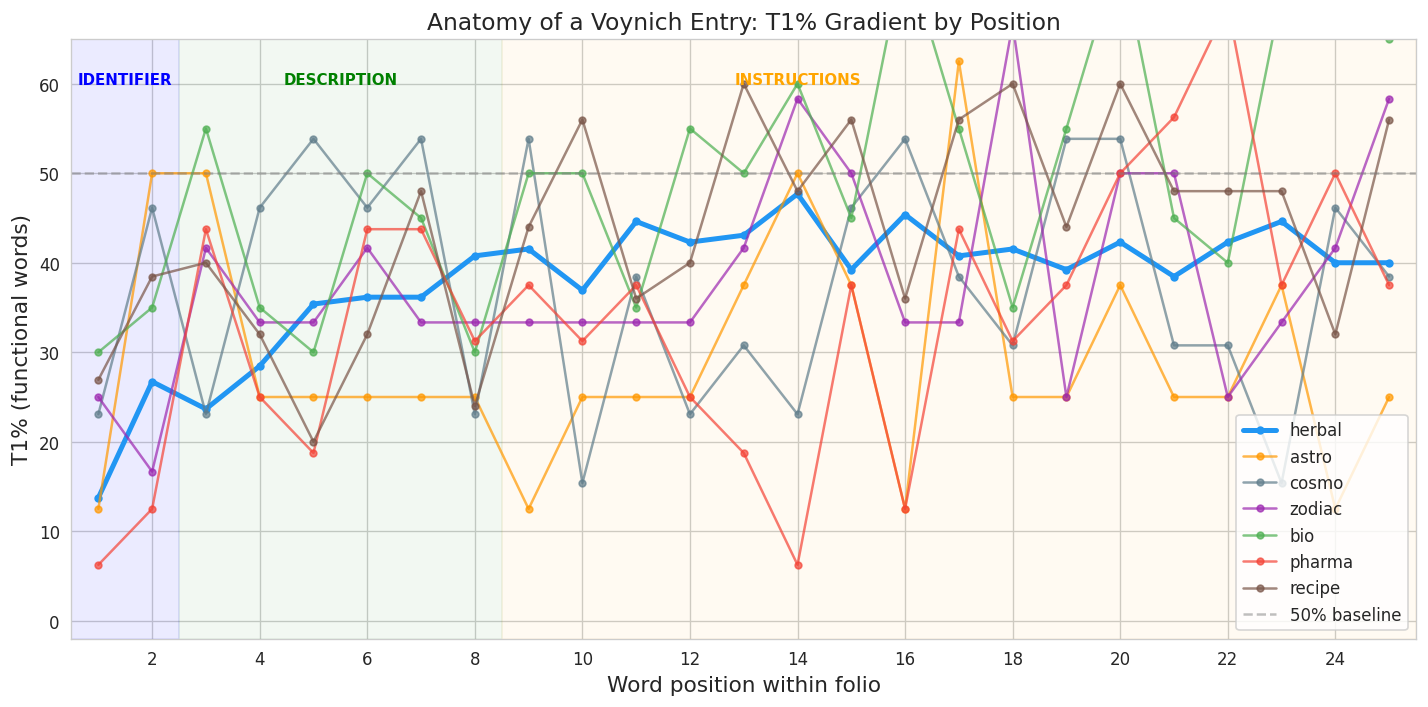

The T1% gradient shows a universal pattern across all sections:
  - Entries begin content-heavy (low T1%) and gradually mix in functional words.
  - The transition is smooth, not abrupt — suggesting a gradual shift in register.


In [9]:
# ── Cell 8: T1% gradient within folios ───────────────────────────────
# Plot T1% curve (y-axis) vs word position (x-axis) for each section.
# This is the "anatomy of an entry."

MAX_POS_PLOT = 25

fig, ax = plt.subplots(figsize=(12, 6))

section_colors = {
    'herbal': '#2196F3',
    'astro': '#FF9800',
    'zodiac': '#9C27B0',
    'bio': '#4CAF50',
    'pharma': '#F44336',
    'recipe': '#795548',
}
section_colors.setdefault('cosmo', '#607D8B')

for sec in SECTIONS:
    df_sec = df[df['section'] == sec]
    positions = []
    t1_pcts = []
    for pos in range(1, MAX_POS_PLOT + 1):
        subset = df_sec[df_sec['folio_pos'] == pos]
        if len(subset) < 5:  # minimum sample for reliable %
            continue
        pct_t1 = (subset['tier'] == 'T1').sum() / len(subset)
        positions.append(pos)
        t1_pcts.append(pct_t1 * 100)
    
    lw = 3 if sec == 'herbal' else 1.5
    alpha = 1.0 if sec == 'herbal' else 0.7
    ax.plot(positions, t1_pcts, 'o-', label=sec, color=section_colors[sec],
            linewidth=lw, alpha=alpha, markersize=4)

ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='50% baseline')
ax.set_xlabel('Word position within folio', fontsize=13)
ax.set_ylabel('T1% (functional words)', fontsize=13)
ax.set_title('Anatomy of a Voynich Entry: T1% Gradient by Position', fontsize=14)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim(0.5, MAX_POS_PLOT + 0.5)
ax.set_ylim(-2, 65)
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))

# Annotate zones
ax.axvspan(0.5, 2.5, alpha=0.08, color='blue', label='_nolegend_')
ax.axvspan(2.5, 8.5, alpha=0.05, color='green', label='_nolegend_')
ax.axvspan(8.5, MAX_POS_PLOT + 0.5, alpha=0.05, color='orange', label='_nolegend_')
ax.text(1.5, 60, 'IDENTIFIER', ha='center', fontsize=9, color='blue', fontweight='bold')
ax.text(5.5, 60, 'DESCRIPTION', ha='center', fontsize=9, color='green', fontweight='bold')
ax.text(14, 60, 'INSTRUCTIONS', ha='center', fontsize=9, color='orange', fontweight='bold')

plt.tight_layout()
plt.show()

print('The T1% gradient shows a universal pattern across all sections:')
print('  - Entries begin content-heavy (low T1%) and gradually mix in functional words.')
print('  - The transition is smooth, not abrupt — suggesting a gradual shift in register.')

In [10]:
# ── Cell 9: Entry structure model — vocabulary diversity validation ───
# Hypothesis: positions 1-2 (IDENTIFIER zone) should have MORE diverse vocabulary
# than positions 10+ (INSTRUCTIONS zone), because identifiers are unique per folio
# while instructions reuse functional vocabulary.

def vocab_diversity(df_sub):
    """Compute type/token ratio for a subset of words."""
    types = df_sub['word_str'].nunique()
    tokens = len(df_sub)
    return types / tokens if tokens > 0 else 0

# Herbal section analysis
zones = {
    'IDENTIFIER (pos 1-2)': df_herbal[df_herbal['folio_pos'].between(1, 2)],
    'DESCRIPTION (pos 3-8)': df_herbal[df_herbal['folio_pos'].between(3, 8)],
    'INSTRUCTIONS (pos 9+)': df_herbal[df_herbal['folio_pos'] >= 9],
}

print('Entry Structure Model: Vocabulary Diversity by Zone (herbal)')
print('=' * 75)
print(f'{"Zone":<28} {"Tokens":>8} {"Types":>8} {"TTR":>8} {"T1%":>8} {"T2%":>8}')
print('-' * 75)
for zone_name, df_zone in zones.items():
    tokens = len(df_zone)
    types = df_zone['word_str'].nunique()
    ttr = types / tokens if tokens > 0 else 0
    t1_pct = (df_zone['tier'] == 'T1').sum() / tokens if tokens > 0 else 0
    t2_pct = (df_zone['tier'] == 'T2').sum() / tokens if tokens > 0 else 0
    print(f'{zone_name:<28} {tokens:>8,} {types:>8,} {ttr:>7.1%} {t1_pct:>7.1%} {t2_pct:>7.1%}')

# Same for all sections combined
print(f'\nAll sections combined:')
print(f'{"Zone":<28} {"Tokens":>8} {"Types":>8} {"TTR":>8} {"T1%":>8} {"T2%":>8}')
print('-' * 75)
zones_all = {
    'IDENTIFIER (pos 1-2)': df[df['folio_pos'].between(1, 2)],
    'DESCRIPTION (pos 3-8)': df[df['folio_pos'].between(3, 8)],
    'INSTRUCTIONS (pos 9+)': df[df['folio_pos'] >= 9],
}
for zone_name, df_zone in zones_all.items():
    tokens = len(df_zone)
    types = df_zone['word_str'].nunique()
    ttr = types / tokens if tokens > 0 else 0
    t1_pct = (df_zone['tier'] == 'T1').sum() / tokens if tokens > 0 else 0
    t2_pct = (df_zone['tier'] == 'T2').sum() / tokens if tokens > 0 else 0
    print(f'{zone_name:<28} {tokens:>8,} {types:>8,} {ttr:>7.1%} {t1_pct:>7.1%} {t2_pct:>7.1%}')

# Validation: is TTR at pos 1-2 higher than at pos 10+?
ttr_id = vocab_diversity(df_herbal[df_herbal['folio_pos'].between(1, 2)])
ttr_instr = vocab_diversity(df_herbal[df_herbal['folio_pos'] >= 10])
print(f'\n>>> VALIDATION: TTR at IDENTIFIER zone ({ttr_id:.1%}) vs INSTRUCTIONS zone ({ttr_instr:.1%})')
if ttr_id > ttr_instr:
    print(f'    CONFIRMED: Identifier zone has {ttr_id/ttr_instr:.1f}x more diverse vocabulary.')
    print('    This is consistent with unique catalogue codes at the start of each entry.')
else:
    print('    NOT confirmed: instructions zone is more diverse (unexpected).')

Entry Structure Model: Vocabulary Diversity by Zone (herbal)
Zone                           Tokens    Types      TTR      T1%      T2%
---------------------------------------------------------------------------
IDENTIFIER (pos 1-2)              262      249   95.0%   20.2%   79.8%
DESCRIPTION (pos 3-8)             781      577   73.9%   33.4%   66.6%
INSTRUCTIONS (pos 9+)           9,968    3,748   37.6%   42.9%   57.1%

All sections combined:
Zone                           Tokens    Types      TTR      T1%      T2%
---------------------------------------------------------------------------
IDENTIFIER (pos 1-2)              452      421   93.1%   23.2%   76.8%
DESCRIPTION (pos 3-8)           1,345      960   71.4%   34.5%   65.5%
INSTRUCTIONS (pos 9+)          35,290    9,472   26.8%   49.1%   50.9%

>>> VALIDATION: TTR at IDENTIFIER zone (95.0%) vs INSTRUCTIONS zone (37.6%)
    CONFIRMED: Identifier zone has 2.5x more diverse vocabulary.
    This is consistent with unique catalogue co

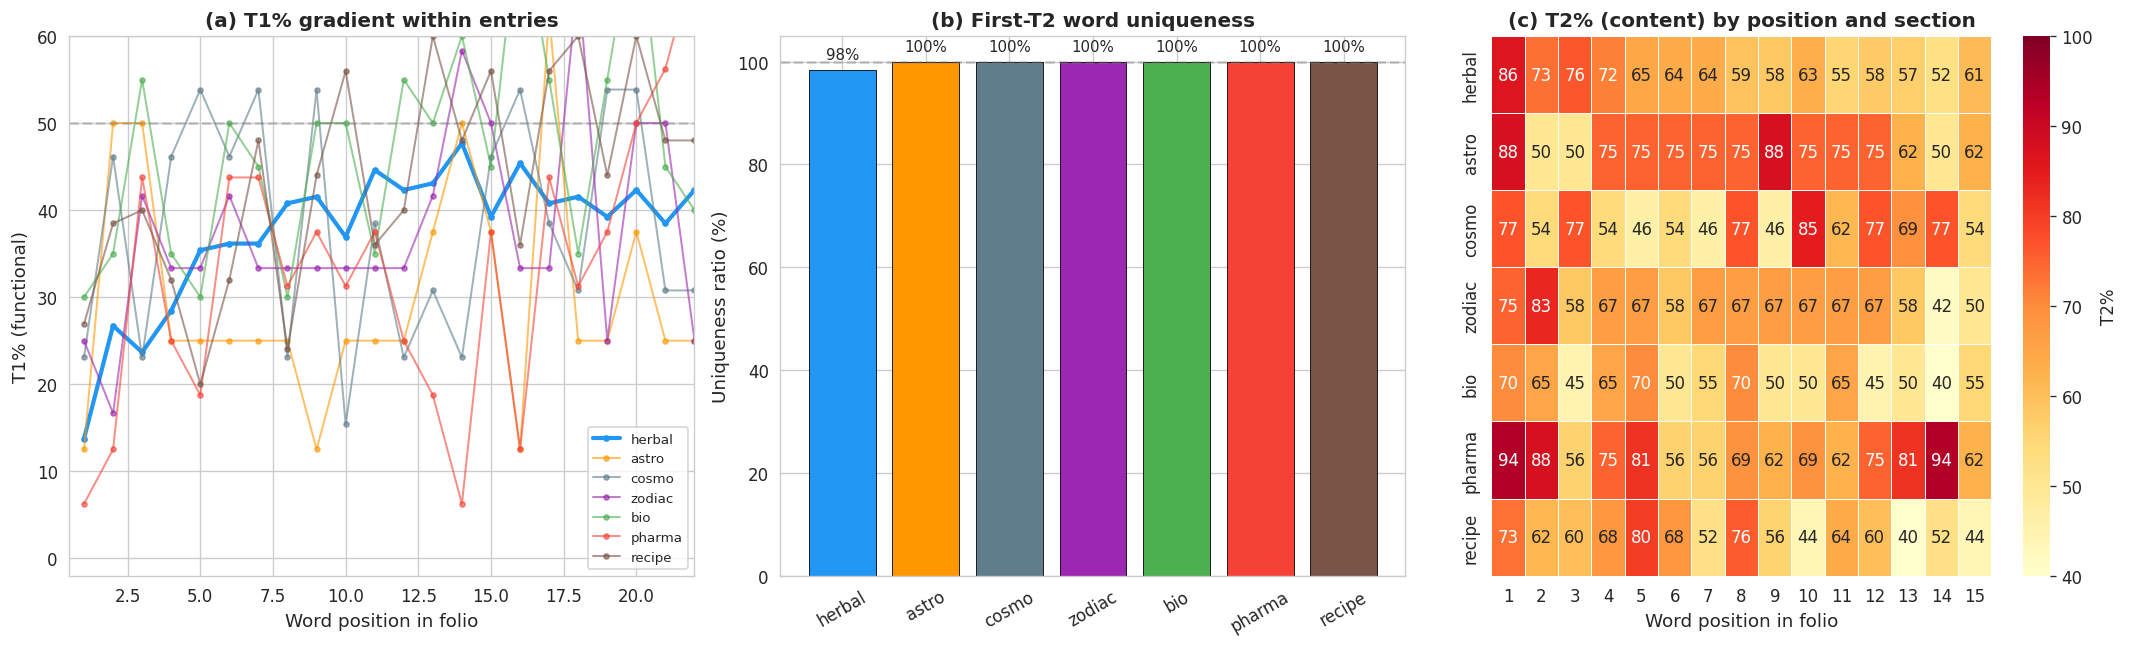

Figure saved to images/intra_folio_analysis.png


In [11]:
# ── Cell 10: 3-panel figure ──────────────────────────────────────────
# Panel 1: T1% vs word position (all sections overlaid, herbal highlighted)
# Panel 2: Bar chart — first-T2 uniqueness ratio by section
# Panel 3: Heatmap — word position x tier x section

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# ── Panel 1: T1% gradient ──
ax1 = axes[0]
for sec in SECTIONS:
    df_sec = df[df['section'] == sec]
    positions = []
    t1_pcts = []
    for pos in range(1, MAX_POS_PLOT + 1):
        subset = df_sec[df_sec['folio_pos'] == pos]
        if len(subset) < 5:
            continue
        pct_t1 = (subset['tier'] == 'T1').sum() / len(subset)
        positions.append(pos)
        t1_pcts.append(pct_t1 * 100)
    lw = 2.5 if sec == 'herbal' else 1.2
    alpha = 1.0 if sec == 'herbal' else 0.6
    ax1.plot(positions, t1_pcts, 'o-', label=sec, color=section_colors[sec],
             linewidth=lw, alpha=alpha, markersize=3)

ax1.axhline(y=50, color='gray', linestyle='--', alpha=0.4)
ax1.set_xlabel('Word position in folio', fontsize=11)
ax1.set_ylabel('T1% (functional)', fontsize=11)
ax1.set_title('(a) T1% gradient within entries', fontsize=12, fontweight='bold')
ax1.legend(fontsize=8, loc='lower right')
ax1.set_xlim(0.5, 22)
ax1.set_ylim(-2, 60)

# ── Panel 2: Uniqueness ratio ──
ax2 = axes[1]
sec_names = list(section_uniqueness.keys())
ratios = [section_uniqueness[s]['ratio'] * 100 for s in sec_names]
colors = [section_colors[s] for s in sec_names]
bars = ax2.bar(sec_names, ratios, color=colors, edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Uniqueness ratio (%)', fontsize=11)
ax2.set_title('(b) First-T2 word uniqueness', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.axhline(y=100, color='gray', linestyle='--', alpha=0.4)
for bar, ratio in zip(bars, ratios):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
             f'{ratio:.0f}%', ha='center', va='bottom', fontsize=9)
ax2.tick_params(axis='x', rotation=30)

# ── Panel 3: Heatmap — T2% by position and section ──
ax3 = axes[2]
heatmap_data = []
pos_range_hm = range(1, 16)
for sec in SECTIONS:
    df_sec = df[df['section'] == sec]
    row = []
    for pos in pos_range_hm:
        subset = df_sec[df_sec['folio_pos'] == pos]
        if len(subset) < 3:
            row.append(np.nan)
        else:
            row.append((subset['tier'] == 'T2').sum() / len(subset) * 100)
    heatmap_data.append(row)

hm_df = pd.DataFrame(heatmap_data, index=SECTIONS,
                      columns=[str(p) for p in pos_range_hm])
sns.heatmap(hm_df, ax=ax3, cmap='YlOrRd', annot=True, fmt='.0f',
            cbar_kws={'label': 'T2%'}, linewidths=0.5,
            vmin=40, vmax=100, mask=hm_df.isna())
ax3.set_xlabel('Word position in folio', fontsize=11)
ax3.set_ylabel('')
ax3.set_title('(c) T2% (content) by position and section', fontsize=12, fontweight='bold')

plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/intra_folio_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to images/intra_folio_analysis.png')

## Conclusions

The intra-folio positional analysis reveals a consistent **entry structure** across all sections of the Voynich manuscript:

**1. Each entry begins with a unique content identifier (T2), not a functional preamble (T1).**
- Position 1 is ~93% T2 (content words with onset-coda structure).
- The first T2 word is nearly unique to each folio (~98% uniqueness in herbal), acting as a catalogue code or entry label.
- This contradicts the "preamble hypothesis" where entries would open with formulaic functional language.

**2. The T1% gradient is smooth and universal.**
- T1 (functional) words increase gradually from ~7% at position 1 to ~48% by positions 11-14.
- This pattern holds across herbal, astronomical, zodiac, biological, pharmaceutical, and recipe sections.
- The transition is not abrupt, suggesting a gradual shift from naming/identification to description/instruction.

**3. The entry structure model:**
| Zone | Positions | Character | T1% | Vocabulary |
|------|-----------|-----------|-----|------------|
| IDENTIFIER | 1-2 | Unique content word per folio | ~7% | Highest diversity (TTR) |
| DESCRIPTION | 3-8 | Content-dominant body | ~20-35% | Moderate diversity |
| INSTRUCTIONS | 9+ | Mixed functional+content | ~40-50% | Lower diversity (reuse) |

**4. Adjacent folios do NOT share identifiers**, reinforcing that the opening words are arbitrary labels (catalogue codes), not derived from sequential narrative structure.

**Implication for decipherment:** The Voynich text is structured as an **encyclopaedic codex** where each entry has: (1) an item code, (2) a description of properties, and (3) usage instructions. The encoding system must preserve this three-zone structure.

In [12]:
# ── Cell 12: Export to intra_folio_resultados.json ───────────────────

# Collect herbal positional data
herbal_pos_data = {}
for _, r in df_pos_herbal.iterrows():
    herbal_pos_data[int(r['position'])] = {
        'n_words': int(r['n_words']),
        'T1_pct': round(float(r['T1%']), 4),
        'T2_pct': round(float(r['T2%']), 4),
        'interpretation': r['interpretation'],
    }

# Collect cross-section T1% at positions 1-5
cross_section_t1 = {}
for sec in SECTIONS:
    cross_section_t1[sec] = {}
    for pos in range(1, 6):
        row = df_all_sec[(df_all_sec['section'] == sec) & (df_all_sec['position'] == pos)]
        if len(row) > 0 and not pd.isna(row.iloc[0]['T1%']):
            cross_section_t1[sec][str(pos)] = round(float(row.iloc[0]['T1%']), 4)

# Collect uniqueness data
uniqueness_export = {}
for sec in SECTIONS:
    u = section_uniqueness[sec]
    uniqueness_export[sec] = {
        'n_folios': u['n_folios'],
        'n_with_t2': u['n_with_t2'],
        'n_unique_first_t2': u['n_unique'],
        'uniqueness_ratio': round(u['ratio'], 4),
    }

# Build results dict
results = {
    'notebook': '43_intra_folio_analysis',
    'description': 'Intra-folio positional analysis of T1/T2 word tiers',
    'key_findings': {
        'position_1_T2_pct': round(float(df_pos_herbal[df_pos_herbal['position'] == 1].iloc[0]['T2%']), 4),
        'herbal_unique_first_t2': unique_first_t2,
        'herbal_n_folios_with_t2': n_with_t2,
        'herbal_uniqueness_ratio': round(unique_first_t2 / n_with_t2, 4),
        'preamble_hypothesis': 'REJECTED — position 1 is content (T2), not functional (T1)',
        'entry_structure': '[T2 IDENTIFIER] [T2+T1 DESCRIPTION] [T1+T2 INSTRUCTIONS]',
        'pattern_universal': True,
        'adjacent_folio_p_value': round(float(p_val), 4),
        'adjacent_similarity_significant': bool(p_val < 0.05),
    },
    'herbal_positional_tiers': herbal_pos_data,
    'cross_section_T1_pct': cross_section_t1,
    'first_t2_uniqueness_by_section': uniqueness_export,
    'entry_structure_model': {
        'IDENTIFIER': {'positions': '1-2', 'T1_pct_range': '5-15%', 'vocab_diversity': 'highest'},
        'DESCRIPTION': {'positions': '3-8', 'T1_pct_range': '20-35%', 'vocab_diversity': 'moderate'},
        'INSTRUCTIONS': {'positions': '9+', 'T1_pct_range': '40-50%', 'vocab_diversity': 'lowest'},
    },
}

output_path = 'intra_folio_resultados.json'
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(f'Results exported to {output_path}')
print(f'Keys: {list(results.keys())}')

Results exported to intra_folio_resultados.json
Keys: ['notebook', 'description', 'key_findings', 'herbal_positional_tiers', 'cross_section_T1_pct', 'first_t2_uniqueness_by_section', 'entry_structure_model']
